Practical 1: describing and representing data


Task 1 — Read the data in

In [27]:
import pandas as pd
import numpy as np
from pathlib import Path

def find_qm_root(start_path: Path = Path.cwd(), anchor: str = "_quarto.yml") -> Path:
    """Walk up from start_path until we find the folder holding _quarto.yml."""
    for parent in [start_path] + list(start_path.parents):
        if (parent / anchor).exists() or parent.name == anchor:
            return parent
    raise FileNotFoundError(f"Anchor '{anchor}' not found in path hierarchy.")

# base_path = (find_qm_root() / "sessions" / "data"
#              / "Performancetables_130242" / "2022-2023")

base_path = (Path.cwd() / "../data"
             / "Performancetables_130242" / "2022-2023")

na_all = ["", "NA", "SUPP", "NP", "NE", "SP", "SN", "LOWCOV", "NEW", "SUPPMAT"]

ks4 = pd.read_csv(base_path / "england_ks4final.csv",
                  na_values=na_all, dtype={"URN": str}, low_memory=False)
ks4 = ks4[ks4["URN"].notna()]
ks4 = ks4[["URN", "ATT8SCR", "P8MEA", "TOTPUPS", "TPUP", "PTFSM6CLA1A", "PTPRIORLO"]]
for c in ks4.columns.drop("URN"):
    ks4[c] = pd.to_numeric(ks4[c].astype(str).str.replace("%", "", regex=False),
                           errors="coerce")

absence = pd.read_csv(base_path / "england_abs.csv",
                      na_values=na_all, dtype={"URN": str}, low_memory=False)
absence = absence[absence["URN"].notna()].drop_duplicates("URN")
absence = absence[["URN", "PERCTOT"]]
absence["PERCTOT"] = pd.to_numeric(absence["PERCTOT"], errors="coerce")

school_info = pd.read_csv(base_path / "england_school_information.csv",
                          na_values=na_all, dtype={"URN": str}, low_memory=False)
school_info = school_info[["URN", "SCHNAME", "LANAME", "MINORGROUP",
                           "OFSTEDRATING", "ADMPOL", "RELCHAR", "GENDER"]]

schools = ks4.merge(school_info, on="URN", how="left") \
             .merge(absence, on="URN", how="left")

len(schools)

5657

Task 2 — First look: what have you got?

In [7]:
print(schools.shape)

(5657, 15)


In [8]:
schools.info()

<class 'pandas.DataFrame'>
RangeIndex: 5657 entries, 0 to 5656
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   URN           5657 non-null   str    
 1   ATT8SCR       4631 non-null   float64
 2   P8MEA         3616 non-null   float64
 3   TOTPUPS       5586 non-null   float64
 4   TPUP          5533 non-null   float64
 5   PTFSM6CLA1A   3979 non-null   float64
 6   PTPRIORLO     3979 non-null   float64
 7   SCHNAME       5657 non-null   str    
 8   LANAME        5657 non-null   str    
 9   MINORGROUP    5657 non-null   str    
 10  OFSTEDRATING  4816 non-null   str    
 11  ADMPOL        5211 non-null   str    
 12  RELCHAR       3215 non-null   str    
 13  GENDER        5657 non-null   str    
 14  PERCTOT       4154 non-null   float64
dtypes: float64(7), str(8)
memory usage: 1.1 MB


Question.
How many rows are there, and how many of them actually have an Attainment 8 score? Why might those two numbers differ?

In [15]:
# fill in the blanks
print(len(schools)) # How many rows are there
print(schools['ATT8SCR'].notna().sum())  # how many of them actually have an Attainment 8 score

5657
4631


Task 3 — What kind of variables are these?

Getting the type wrong, in code

In [16]:
# As it arrives: just text
sorted(schools["OFSTEDRATING"].dropna().unique())
# That is not a ranking — it is the alphabet. Every table you group by it, every plot you facet by it, and every axis you draw will come out in that order, and none of them will warn you.

['Good',
 'Inadequate',
 'Outstanding',
 'Requires improvement',
 'Serious Weaknesses',
 'Special Measures']

The fix is to store it as an ordered type, stating the order yourself. But there is a trap inside the fix, so we check as we go:

In [17]:
import pandas as pd

rating_order = ["Special Measures", "Serious Weaknesses", "Inadequate",
                "Requires improvement", "Good", "Outstanding"]

before = schools["OFSTEDRATING"].isna().sum()

schools["OFSTEDRATING"] = pd.Categorical(schools["OFSTEDRATING"],
                                         categories=rating_order,
                                         ordered=True)

print({"missing_before": int(before),
       "missing_after": int(schools["OFSTEDRATING"].isna().sum())})

{'missing_before': 841, 'missing_after': 841}



Both factor() and pd.Categorical() turn any value you did not list into a missing value, without a word of warning.

Leave one real category out of rating_order — Inadequate is easy to forget, because most schools in that state are labelled with the more specific Serious Weaknesses or Special Measures — and those schools silently vanish from every table and plot that follows.

If the two numbers above are not identical, you have just deleted data.


Question. Plot mean Attainment 8 by Ofsted rating before and after setting the order. What changes, and what does not?

Answer: The numbers do not change at all — the same schools are in the same groups, and each group’s mean is identical either way.

What changes is the order the categories come out in, and therefore what the chart appears to say. Alphabetically ordered, the bars rise and fall with no pattern and the chart looks like noise. Correctly ordered, you see a clean monotonic climb from Special Measures to Outstanding.

This is the part worth remembering: nothing errored, and no number was wrong. The only thing that was wrong was the story the chart told.

Task 4 — Missing values

In [18]:
cols = ["ATT8SCR", "P8MEA", "PERCTOT", "PTFSM6CLA1A", "OFSTEDRATING"]
print((schools[cols].isna().mean() * 100).round(1))

ATT8SCR         18.1
P8MEA           36.1
PERCTOT         26.6
PTFSM6CLA1A     29.7
OFSTEDRATING    14.9
dtype: float64


In [19]:
tmp = schools[schools["TOTPUPS"].notna()].copy()
tmp["p8"] = np.where(tmp["P8MEA"].isna(),
                     "Progress 8 missing", "Progress 8 present")
print(tmp.groupby("p8")["TOTPUPS"].agg(schools="size", median_pupils="median"))

                    schools  median_pupils
p8                                        
Progress 8 missing     1981          126.0
Progress 8 present     3605         1019.0


Task 5 — Describe one continuous variable

In [20]:
schools["ATT8SCR"].describe()

count    4631.000000
mean       39.768063
std        17.529873
min         0.000000
25%        34.500000
50%        43.600000
75%        50.200000
max        87.600000
Name: ATT8SCR, dtype: float64

Q. Is the mean above or below the median? What does that suggest about the shape of the data — even before you have plotted anything? (You will get to plot it properly next week.)

Task 6 — Compare groups with boxplots and violins

In [21]:
mainstream = schools[
    schools["MINORGROUP"].isin(["Academy", "Maintained school"])
    & schools["ATT8SCR"].notna()
].copy()

len(mainstream)

3250

A worked example: admissions policy

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

sub = mainstream[mainstream["ADMPOL"].notna()]

print(sub.groupby("ADMPOL")["ATT8SCR"]
         .agg(n="size", mean="mean", median="median", sd="std")
         .round(1)
         .sort_values("n", ascending=False))

mkdir -p failed for path /home/jovyan/.config/matplotlib: [Errno 13] Permission denied: '/home/jovyan/.config/matplotlib'
Matplotlib created a temporary cache directory at /tmp/matplotlib-3m5v1u2i because there was an issue with the default path (/home/jovyan/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
Matplotlib is building the font cache; this may take a moment.


                   n  mean  median   sd
ADMPOL                                 
Non-selective   2815  45.9    45.5  7.2
Selective        163  71.7    72.5  7.3
Not applicable    50  43.4    41.4  8.7


/tmp/ipykernel_31133/3740570406.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=sub, x="ATT8SCR", y="ADMPOL", scale="count",
/tmp/ipykernel_31133/3740570406.py:2: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='count'` for the same effect.
  sns.violinplot(data=sub, x="ATT8SCR", y="ADMPOL", scale="count",


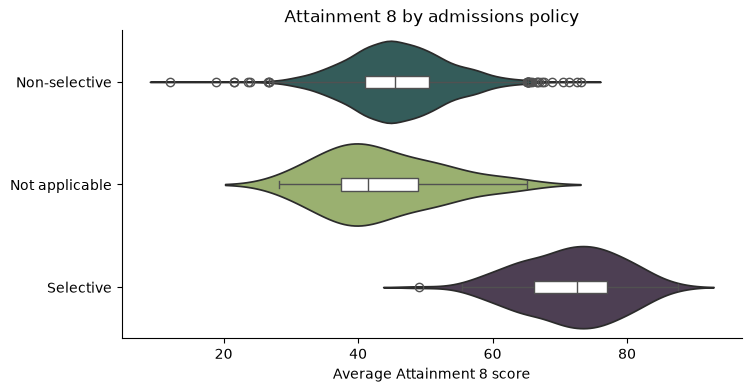

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.violinplot(data=sub, x="ATT8SCR", y="ADMPOL", scale="count",
               inner=None, palette=["#2E6260", "#9DBB65", "#4E3C56"], ax=ax)
sns.boxplot(data=sub, x="ATT8SCR", y="ADMPOL", width=0.12,
            showfliers=True, boxprops={"facecolor": "white"}, ax=ax)
ax.set_title("Attainment 8 by admissions policy")
ax.set_xlabel("Average Attainment 8 score")
ax.set_ylabel("")
sns.despine()
plt.show()



The violin is scaled by count, so its width tells you how many schools are in each group. A boxplot alone would draw the 163 selective schools and the 2,815 non-selective ones at exactly the same size, which would badly mislead you about how much evidence sits behind each summary.

Questions
1. How big is the gap in mean Attainment 8 between selective and non-selective schools?
2. Is the spread different too, or only the middle?
3. Does this tell you selective schools teach better? What else could explain it?

Repeat the table and the plot above using a different grouping variable. Choose one of:

OFSTEDRATING — the Ofsted judgement
GENDER — mixed, boys, or girls
RELCHAR — religious character
LANAME — local authority (pick a handful, there are 150)

           n  mean  median    sd
GENDER                          
Mixed   2897  45.4    45.0   7.8
Girls    205  59.8    57.9  10.7
Boys     148  58.3    56.1  12.9


/tmp/ipykernel_31133/3699004172.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=sub_gender, x="ATT8SCR", y="GENDER", scale="count",
/tmp/ipykernel_31133/3699004172.py:9: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='count'` for the same effect.
  sns.violinplot(data=sub_gender, x="ATT8SCR", y="GENDER", scale="count",


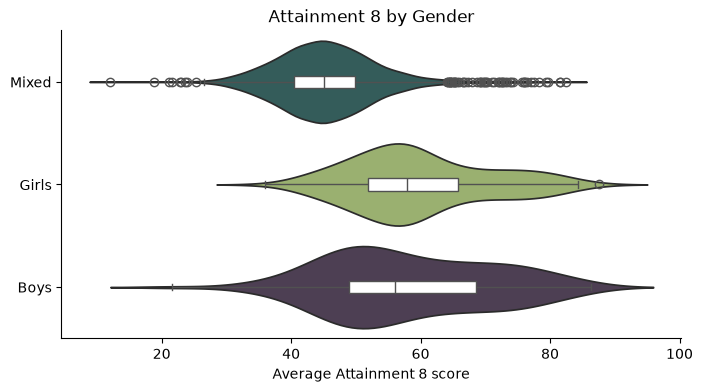

In [26]:
sub_gender = mainstream[mainstream["GENDER"].notna()]

print(sub_gender.groupby("GENDER")["ATT8SCR"]
         .agg(n="size", mean="mean", median="median", sd="std")
         .round(1)
         .sort_values("n", ascending=False))

fig, ax = plt.subplots(figsize=(8, 4))
sns.violinplot(data=sub_gender, x="ATT8SCR", y="GENDER", scale="count",
               inner=None, palette=["#2E6260", "#9DBB65", "#4E3C56"], ax=ax)
sns.boxplot(data=sub_gender, x="ATT8SCR", y="GENDER", width=0.12,
            showfliers=True, boxprops={"facecolor": "white"}, ax=ax)
ax.set_title("Attainment 8 by Gender")
ax.set_xlabel("Average Attainment 8 score")
ax.set_ylabel("")
sns.despine()
plt.show()

Task 7 — Write it down

The point of all of the above is to be able to say something defensible. In a few sentences each:

1. What is in this dataset? How many schools, over what period, measuring what?
2. What did you filter out, and what did that change? You dropped special and independent schools. Which questions can you no longer answer?
3. Is the mean a good summary of your chosen variable? What does the gap between mean and median suggest?
4. Which grouping variable did you use, and what did the comparison show?
5. What is missing, and is it missing at random?
6. What would you want to check before claiming that the difference you found is real?

Question 6 is the one the rest of this course exists to answer. Keep your notes — we come back to this data in weeks 5 to 10, and next week you will plot its distribution properly.